# Optimización Bayesiana

**Teorema de Bayes**

$$ P(A|B) = \frac{P(B|A) P(A)}{P(B)} $$

$ P(A|B) $: Probabilidad condicional de A dado B. También conocida como la probabilidad posterior de A dado que B ocurre.

$ P(B|A) $: Probabilidad condicional de B dado A. Se interpreta como la verosimilitud (*likelihood*) de A.

$ P(A) $: Probabilidad de observar A. También conocida como probabilidad a priori.

$ P(B) $: Probabilidad de observar B. Interpretada como evidencia.

Utilizando las definiciones de arriba actualizamos la definición del teorema de bayes:

$$ \text{posterior} = \frac{(\text{verosimilitud})(\text{anterior})}{\text{evidencia}} $$

La intuición es que el teorema de Bayes es una herramienta para actualizar nuestras creencias dado lo que se tenía antes y nueva evidencia. Por ejemplo, tomas una moneda y asumes que es una moneda justa, dado que es lo más probable y que las monedas suelen ser justas en tu experiencia. Lanzas la moneda tres veces y cae sello las tres veces; un poco extraño, así que ajustas tus creencias y empiezas a imaginar que la moneda no es tan justa como debería ser. Lanzas las monedas tres veces y cae águila; ahora crees que la moneda es justa de nuevo.

## ¿Cómo aplicamos esto en nuestra vida diaria?

Imagina que tienes 3 puntos (conocimiento previo) en un espacio.

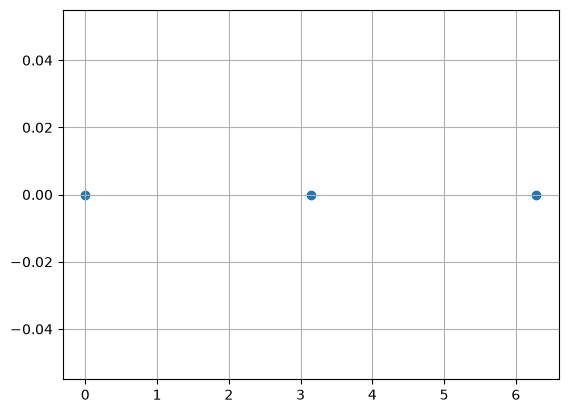

In [21]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
plt.figure(); plt.scatter([0, np.pi, 2*np.pi], [0, 0, 0]); plt.grid()

No hay seguridad de cómo se conectan estos puntos, pero sabes que están conectados. Hay infinitas formas en las que estos puntos se pueden conectar.

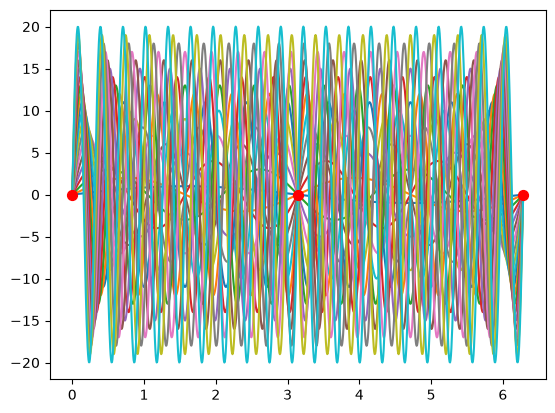

In [22]:
x = np.linspace(0, 2*np.pi, 1000); plt.figure(); 
for i in range(20) :
    y = (i+1)*np.sin((i+1)*x); plt.plot(x, y)
plt.scatter([0, np.pi, 2*np.pi], [0, 0, 0], s=50, c="r", zorder=3)

Hay tanta incertidumbre que decides pedir más información y te dan otro punto.

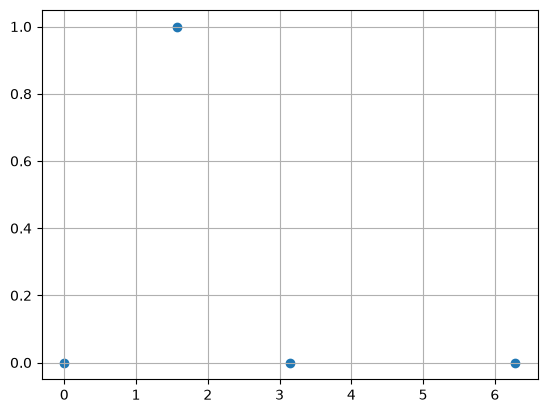

In [23]:
plt.figure(); plt.scatter([0, np.pi, 2*np.pi, np.pi/2], [0, 0, 0, 1]); plt.grid()

Con esta nueva información actualizas tus creencias y reduces la cantidad de formas en las que se conectan estos puntos (siguen siendo infinitas).

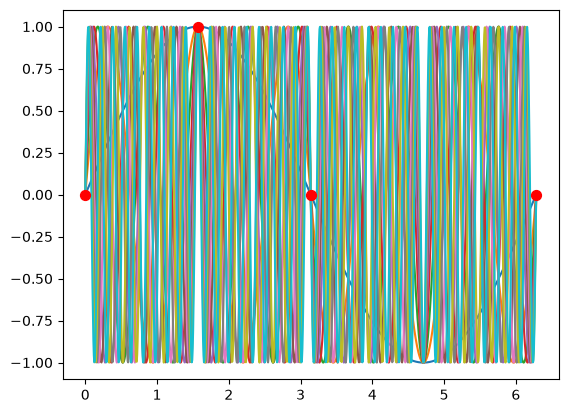

In [24]:
x = np.linspace(0, 2*np.pi, 1000); plt.figure(); 
for i in range(10) :
    y = np.sin((4*i+1)*x); plt.plot(x, y)
plt.scatter([0, np.pi, 2*np.pi, np.pi/2], [0, 0, 0, 1], s=50, c="r", zorder=3)

Te pones a pensar: "Sí. Teóricamente hay infinitas funciones que pueden conectar estos puntos, pero sólo algunas tienen sentido dado mi contexto."

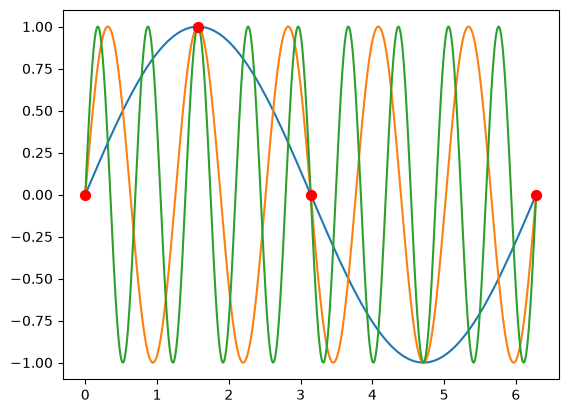

In [25]:
x = np.linspace(0, 2*np.pi, 1000); plt.figure(); 
for i in range(3) :
    y = np.sin((4*i+1)*x); plt.plot(x, y)
plt.scatter([0, np.pi, 2*np.pi, np.pi/2], [0, 0, 0, 1], s=50, c="r", zorder=3)

Ahora sólo quedan algunos pocos candidatos dado el criterio que tienes. Hay incertidumbre sobre cuál de estos candidatos podría ser el que mejor se ajusta, así que decides pedir más información. ¿Qué información serviría más?
- Se podría pedir el valor de $y$ cuando $x=\frac{3\pi}{2}$, pero los candidatos que tenemos todos pasan por el mismo punto. Incluso si nos dieran la información, no ayudaría de mucho.
- Se podría pedir fuera del rango que tenemos, pero quizás la información no existe o dado el contexto del problema es imposible que estos puntos existan.

Nos asignan nuestro último punto.

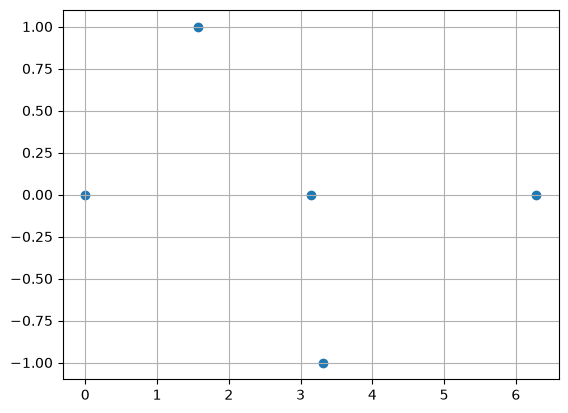

In [26]:
plt.figure(); plt.scatter([0, np.pi, 2*np.pi, np.pi/2, 19*np.pi/18], [0, 0, 0, 1, -1]); plt.grid()

Usamos esta nueva información (evidencia) junto con lo que conocíamos (anterior) y lo que creemos que es posible (verosimilitud) para decidir sobre una nueva función (posterior).

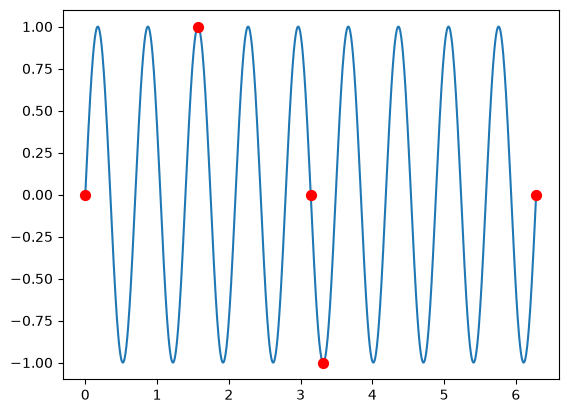

In [27]:
x = np.linspace(0, 2*np.pi, 1000); plt.figure(); y = np.sin(9*x); plt.plot(x, y)
plt.scatter([0, np.pi, 2*np.pi, np.pi/2, 19*np.pi/18], [0, 0, 0, 1, -1], s=50, c="r", zorder=3)

Una forma de realizar este experimento es mediante un proceso gaussiano, que asume que la variable de salida es una variable aleatoria con distribución normal multivariada. Utilicemos la función que encontramos y asumamos que no sabemos cuál es.

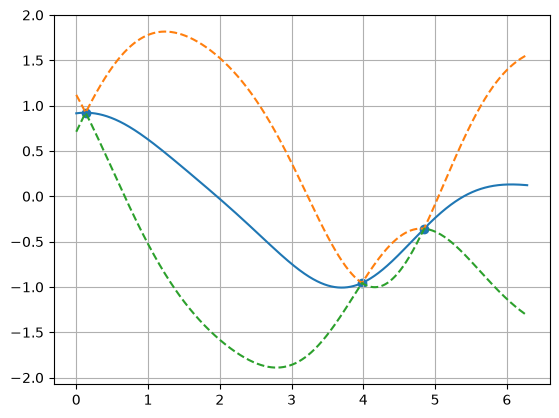

In [28]:
np.random.seed(10)
kernel = 1.0*RBF(length_scale=1.0)
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
def f(x) :
    return np.sin(9*x)
X = np.random.uniform(0, 2*np.pi, 3).reshape([-1, 1])
y = f(X)
gp.fit(X, y)
X_new = np.linspace(0, 2*np.pi, 10000).reshape([-1, 1])
y_pred, desv = gp.predict(X_new, return_std=True)
plt.figure(); plt.scatter(X, f(X)); plt.grid()

# Gráfica para trazar la línea de predicción y la desviación estándar
plt.plot(X_new, y_pred)

# Cálculo de los límites superior e inferior de la predicción considerando la desviación estándar, sin relleno
y_upper = y_pred + 2*desv
y_lower = y_pred - 2*desv
plt.plot(X_new, y_upper, linestyle='--')
plt.plot(X_new, y_lower, linestyle='--')
plt.show()

#Tip para futuro ~ argmax y argmin.
#Si se quiere reducir incertidumbre, se utiliza el intervalo más grande.


Realizamos una regresión de proceso gaussiano para encontrar distribuciones que podrían darnos estas muestras

Creamos un vector de valores posibles de $x$ y predecimos $y$ usando el resultado de la regresión.

Graficamos nuestra primera propuesta, utilizando el error estándar para dibujar nuestros intervalos de confianza.

Podemos ver que necesitamos más muestras debido a que hay mucha incertidumbre en algunas partes de nuestro dominio. Hay varios criterios para decidir cómo pedir muestras:
- Maximizar (busco mi predicción del máximo actual y pido esa medida)
- Minimizar (busco mi predicción del mínimo actual y pido esa medida)
- Reducir incertidumbre (busco el punto donde mi intervalo de confianza es más grande y pido esa medida)

Y repetimos el proceso ya con nueva información.

Muestras iniciales generadas: [[  1.44046515]
 [ 11.27381292]
 [  5.83998784]
 [ -5.29069898]
 [-13.82307272]
 [ -3.57268888]]
Valores de y correspondientes a las muestras iniciales: [[ 0.38740561]
 [ 0.80361897]
 [ 0.74941926]
 [ 0.47274302]
 [ 0.95087545]
 [-0.67301183]]


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


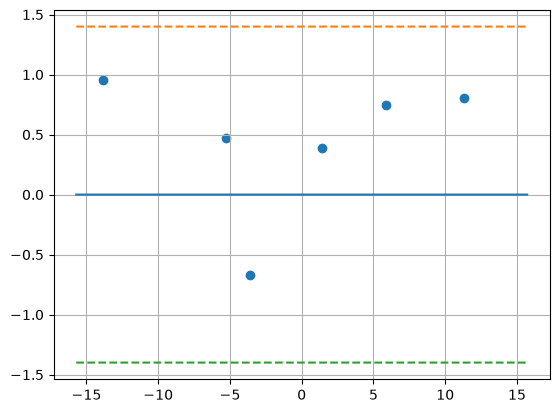

In [29]:
np.random.seed(67)
# Los 6 valores generados de las muestras iniciales U(-5pi, 5pi) y hacer la gráfica correspondiente con la funcion f(X)
X = np.random.uniform(-5*np.pi, 5*np.pi, 6).reshape([-1, 1])
print("Muestras iniciales generadas:", X)
y = f(X)
print("Valores de y correspondientes a las muestras iniciales:", y)

# Ajustar el proceso gaussiano con las nuevas muestras
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
gp.fit(X, y)

# Predecir en todo el dominio
X_new = np.linspace(-5*np.pi, 5*np.pi, 10000).reshape([-1, 1])
y_pred, desv = gp.predict(X_new, return_std=True)

# Gráfica de las muestras, la predicción y los límites con 2 desviaciones estándar
plt.figure(); plt.scatter(X, f(X)); plt.grid()
plt.plot(X_new, y_pred)
y_upper = y_pred + 2*desv
y_lower = y_pred - 2*desv
plt.plot(X_new, y_upper, linestyle='--')
plt.plot(X_new, y_lower, linestyle='--')
plt.show()

Repitamos el proceso 30 veces con una función distinta.

$$ f(x) = \sin{(\frac{x}{3})} + \cos{(2x)},\ \ \ \ x \in [-5\pi, 5\pi] $$

Iteración 1: siguiente punto x = 15.7080
Iteración 2: siguiente punto x = -9.5687
Iteración 3: siguiente punto x = 8.5570
Iteración 4: siguiente punto x = -1.0478
Iteración 5: siguiente punto x = 13.4929
Iteración 6: siguiente punto x = -15.7080
Iteración 7: siguiente punto x = 3.6462
Iteración 8: siguiente punto x = -11.6046
Iteración 9: siguiente punto x = -7.4605
Iteración 10: siguiente punto x = 9.8829
Iteración 11: siguiente punto x = 7.1337
Iteración 12: siguiente punto x = 0.1869


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Iteración 13: siguiente punto x = -15.7048
Iteración 14: siguiente punto x = -2.3172
Iteración 15: siguiente punto x = 14.6020
Iteración 16: siguiente punto x = -12.7043
Iteración 17: siguiente punto x = 2.5528
Iteración 18: siguiente punto x = 12.3713
Iteración 19: siguiente punto x = -6.3765
Iteración 20: siguiente punto x = 4.7459
Iteración 21: siguiente punto x = -8.5161
Iteración 22: siguiente punto x = -10.5867
Iteración 23: siguiente punto x = -4.4285
Iteración 24: siguiente punto x = -14.6146
Iteración 25: siguiente punto x = 7.8469
Iteración 26: siguiente punto x = 10.5709
Iteración 27: siguiente punto x = -1.6762
Iteración 28: siguiente punto x = 0.8248
Iteración 29: siguiente punto x = 15.2053
Iteración 30: siguiente punto x = 6.4236


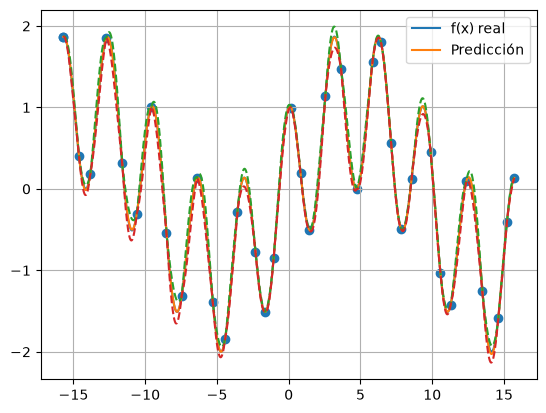

In [30]:
# Nueva función
def f(x) :
    return np.sin(x/3) + np.cos(2*x)

# 6 muestras iniciales U(-5pi, 5pi)
np.random.seed(67)
X = np.random.uniform(-5*np.pi, 5*np.pi, 6).reshape([-1, 1])
y = f(X)
X_new = np.linspace(-5*np.pi, 5*np.pi, 10000).reshape([-1, 1])

# Repetir 30 veces: ajustar, predecir y pedir el punto con mayor incertidumbre
for i in range(30):
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
    gp.fit(X, y)
    y_pred, desv = gp.predict(X_new, return_std=True)
    x_sig = X_new[np.argmax(desv)]
    print(f"Iteración {i+1}: siguiente punto x = {x_sig[0]:.4f}")
    X = np.hstack([X.reshape([-1]), x_sig]).reshape([-1, 1])
    y = f(X)

# Ajuste final con todas las muestras
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
gp.fit(X, y)
y_pred, desv = gp.predict(X_new, return_std=True)

plt.figure(); plt.scatter(X, y); plt.grid()
plt.plot(X_new, f(X_new), label="f(x) real")
plt.plot(X_new, y_pred, label="Predicción")
plt.plot(X_new, y_pred + 2*desv, linestyle='--')
plt.plot(X_new, y_pred - 2*desv, linestyle='--')
plt.legend()
plt.show()

### Actividad

1. Modificar el comportamiento de selección para elegir el máximo de las predicciones como el siguiente punto.
2. Modificar el comportamiento de selección para elegir el mínimo de las predicciones como el siguiente punto.

c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 9 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 1 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 14 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/st

Máximo encontrado: x = 6.241397946150741  f(x) = 1.8694153920250827


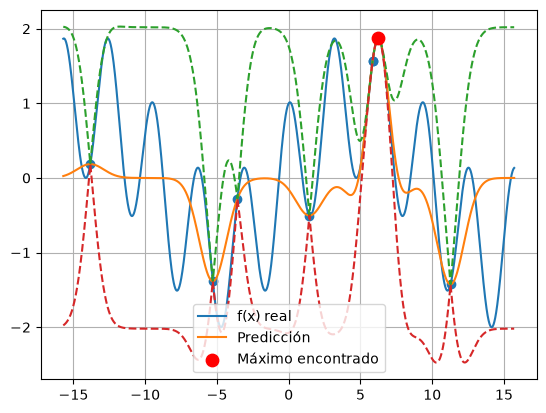

In [31]:
# 1. Elegir el máximo de las predicciones como siguiente punto
np.random.seed(67)
X = np.random.uniform(-5*np.pi, 5*np.pi, 6).reshape([-1, 1])
y = f(X)

for i in range(30):
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
    gp.fit(X, y)
    y_pred, desv = gp.predict(X_new, return_std=True)
    x_sig = X_new[np.argmax(y_pred)]
    X = np.hstack([X.reshape([-1]), x_sig]).reshape([-1, 1])
    y = f(X)

print("Máximo encontrado: x =", X[np.argmax(y)][0], " f(x) =", y.max())

gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
gp.fit(X, y)
y_pred, desv = gp.predict(X_new, return_std=True)

plt.figure(); plt.scatter(X, y); plt.grid()
plt.plot(X_new, f(X_new), label="f(x) real")
plt.plot(X_new, y_pred, label="Predicción")
plt.plot(X_new, y_pred + 2*desv, linestyle='--')
plt.plot(X_new, y_pred - 2*desv, linestyle='--')
plt.scatter(X[np.argmax(y)], y.max(), s=80, c="r", zorder=3, label="Máximo encontrado")
plt.legend()
plt.show()

c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 12 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 7 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 1 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/st

Mínimo encontrado: x = 11.067366858955943  f(x) = -1.5102889390454328


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 6 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 11 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


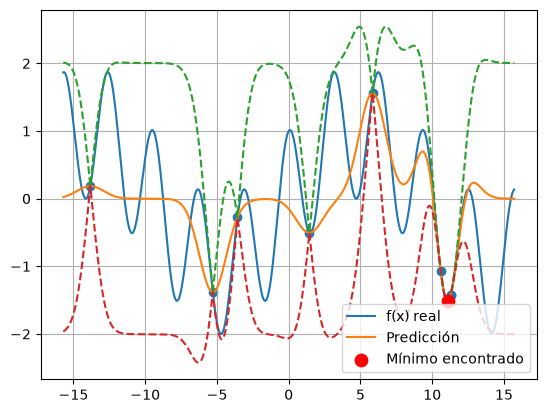

In [32]:
# 2. Elegir el mínimo de las predicciones como siguiente punto
np.random.seed(67)
X = np.random.uniform(-5*np.pi, 5*np.pi, 6).reshape([-1, 1])
y = f(X)

for i in range(30):
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
    gp.fit(X, y)
    y_pred, desv = gp.predict(X_new, return_std=True)
    x_sig = X_new[np.argmin(y_pred)]
    X = np.hstack([X.reshape([-1]), x_sig]).reshape([-1, 1])
    y = f(X)

print("Mínimo encontrado: x =", X[np.argmin(y)][0], " f(x) =", y.min())

gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
gp.fit(X, y)
y_pred, desv = gp.predict(X_new, return_std=True)

plt.figure(); plt.scatter(X, y); plt.grid()
plt.plot(X_new, f(X_new), label="f(x) real")
plt.plot(X_new, y_pred, label="Predicción")
plt.plot(X_new, y_pred + 2*desv, linestyle='--')
plt.plot(X_new, y_pred - 2*desv, linestyle='--')
plt.scatter(X[np.argmin(y)], y.min(), s=80, c="r", zorder=3, label="Mínimo encontrado")
plt.legend()
plt.show()

### Optimización de `C` y `gamma` de un SVC con Default

Uso la optimización bayesiana para buscar los hiperparámetros $H = [C, \gamma]$ de un `SVC` con kernel `rbf`. La función objetivo recibe $H$, crea el modelo, lo evalúa con K-Fold de 5 y regresa el AUC promedio, y el proceso gaussiano decide qué combinación probar después.

In [33]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

df = pd.read_csv("Default.csv", index_col=0)

X_default = df[["balance", "income", "student"]].copy()
X_default["student"] = (df["student"] == "Yes").astype(int)
y_default = (df["default"] == "Yes").astype(int)

numerical_cols = ["balance", "income"]
boolean_cols = ["student"]

# K-Fold con k = 5
kf = KFold(n_splits=5, shuffle=True, random_state=42)


In [38]:
from sklearn.model_selection import cross_val_score
def objetivo(H):
    C = H[0]
    gamma = H[1]
    scores = []

    
    preprocessor = ColumnTransformer(transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("bool", "passthrough", boolean_cols)
    ])
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", SVC(kernel="rbf", C=C, gamma=gamma, probability=True, random_state=42))
    ])
    scores = cross_val_score(pipeline, X_default, y_default, cv=kf, scoring="roc_auc")


    return np.mean(scores)


In [39]:
# Combinaciones posibles de C en [0.1, 50] y gamma en [0.001, 1]
candidatos = []
for c in np.linspace(0.1, 50, 100):
    for g in np.linspace(0.001, 1, 100):
        candidatos.append([c, g])
H_new = np.array(candidatos)

# 5 combinaciones iniciales al azar
np.random.seed(67)
C_ini = np.random.uniform(0.1, 50, 5)
gamma_ini = np.random.uniform(0.001, 1, 5)

# H es una lista de [C, gamma]
H = []
auc = []
for i in range(5):
    H.append([C_ini[i], gamma_ini[i]])
    auc.append(objetivo(H[i]))
    print(f"C = {H[i][0]:.4f}, gamma = {H[i][1]:.4f}, AUC = {auc[-1]:.4f}")


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\

C = 27.3380, gamma = 0.3869, AUC = 0.8016


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\

C = 42.9569, gamma = 0.2139, AUC = 0.8375


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\

C = 34.3260, gamma = 0.9326, AUC = 0.8154


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\

C = 16.6464, gamma = 0.7231, AUC = 0.7747


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\

C = 3.0939, gamma = 0.0478, AUC = 0.7527


In [36]:
# 30 iteraciones: ajustar el proceso gaussiano y pedir el siguiente punto
for i in range(30):
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
    # np.array(H) convierte la lista en la matriz de C y gamma
    gp.fit(np.array(H), auc)
    y_pred, desv = gp.predict(H_new, return_std=True)

    # El límite superior junta el máximo de la predicción con la incertidumbre
    h_sig = H_new[np.argmax(y_pred + 2*desv)]
    H.append([h_sig[0], h_sig[1]])
    auc.append(objetivo(h_sig))
    print(f"Iteración {i+1}: C = {h_sig[0]:.4f}, gamma = {h_sig[1]:.4f}, AUC = {auc[-1]:.4f}")


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\

Iteración 1: C = 50.0000, gamma = 0.0010, AUC = 0.8944


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\

Iteración 2: C = 48.9919, gamma = 0.6670, AUC = 0.8099


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\

...

Iteración 28: C = 45.4636, gamma = 1.0000, AUC = 0.8204


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 9 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Pyt

Iteración 29: C = 7.6606, gamma = 0.0010, AUC = 0.8869


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\

Iteración 30: C = 11.6929, gamma = 1.0000, AUC = 0.7810


In [37]:
resultados = pd.DataFrame(H, columns=["C", "gamma"])
resultados["AUC promedio"] = auc

print("Mejor combinación: C =", H[np.argmax(auc)][0], " gamma =", H[np.argmax(auc)][1], " AUC =", max(auc))
resultados.round(4)


Mejor combinación: C = 18.24545454545455  gamma = 0.001  AUC = 0.9042510266634871


,C,gamma,AUC promedio
0,27.3380,0.3869,0.8016
1,42.9569,0.2139,0.8375
2,34.3260,0.9326,0.8154
3,16.6464,0.7231,0.7747
4,3.0939,0.0478,0.7527
5,50.0000,0.0010,0.8944
6,48.9919,0.6670,0.8099
7,35.3828,0.0010,0.8946
8,9.6768,0.0010,0.8990
9,8.1646,1.0000,0.7643
